# 02 - Model Training & Validation Orchestration (U-Net ResNet34 v2)

**Competition:** Solar Filament Segmentation Challenge 2026  
**Experiment:** U-Net with ImageNet-pretrained ResNet34 Backbone (v2 - EDA-Informed)  
**Key Improvements from Audit:**
- Pretrained ImageNet weights adapted to 1-channel grayscale input.
- Calibrated positive loss weighting (`pos_weight=8.0` vs. 30.0) to eliminate massive false positives.
- Foreground-aware 512x512 patch cropping (`foreground_prob=0.7`).
- Mixed precision with PyTorch AMP GradScaler, unscaling, and gradient clipping (`max_norm=1.0`).
- Separate experiment directory: `checkpoints/unet_resnet34_v2/` preserving original baseline weights.
- Resumable training loop from `checkpoints/unet_resnet34_v2/latest.pth`.
- Full-resolution tiled evaluation and baseline comparison workflow.

> **Principle:** Kaggle notebooks import modular Python components from `src/filament_seg/`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset

cwd = Path.cwd().resolve()
project_root = cwd if (cwd / 'src' / 'filament_seg' / 'dataset.py').is_file() else cwd.parent
assert (project_root / 'src' / 'filament_seg' / 'dataset.py').is_file(), cwd
if str(project_root / 'src') not in sys.path:
    sys.path.insert(0, str(project_root / 'src'))

from filament_seg.utils import set_seed, load_config, get_device, get_logger
from filament_seg.model import build_model
from filament_seg.losses import BCEDiceLoss
from filament_seg.evaluate import compute_dice, compute_iou, evaluate_semantic_predictions, compare_models
from filament_seg.dataset import SolarFilamentDataset
from filament_seg.preprocessing import ForegroundAwareCrop, get_train_transform, get_val_transform
from filament_seg.train import load_checkpoint, save_checkpoint, train_v2_model, validate_one_epoch

config_path = project_root / 'configs' / 'unet_resnet34_v2.yaml'
config = load_config(config_path if config_path.is_file() else project_root / 'configs' / 'baseline.yaml')
set_seed(config['project']['seed'])
device = get_device(config['training'].get('device'))
print(f'Python: {sys.executable}')
print(f'Project root: {project_root}')
print(f'Device selected: {device}')
print(f'Experiment: {config["project"]["experiment_name"]}')

Python: C:\Users\Vinny\Project\Kaggle\Solar Filament Segmentation\.conda\python.exe
Project root: C:\Users\Vinny\Project\Kaggle\Solar Filament Segmentation
Device selected: cuda
Experiment: unet-resnet34-v2


## 1. Dataset and Deterministic Physical-Image Split

Split 707 physical filenames once (seed 42, 80/20: 565 train / 142 val) ensuring zero leakage across splits.

In [2]:
train_dir = project_root / 'data' / 'filament-segmentation-2026' / 'MAGFiLO_1.0_Kaggle_2026' / 'train'
image_dir = train_dir / 'train_images'
annotation_path = train_dir / 'MAGFiLO_1.0_Annotations_kaggle2026_train.json'

train_dataset = SolarFilamentDataset(image_dir, annotation_path, transform=get_train_transform(512))
val_dataset = SolarFilamentDataset(image_dir, annotation_path, transform=get_val_transform(512))
val_eval_dataset = SolarFilamentDataset(image_dir, annotation_path)
assert len(train_dataset) == len(val_dataset) == len(val_eval_dataset) == 707

indices = np.random.default_rng(config['project']['seed']).permutation(len(train_dataset))
train_indices = indices[:565].tolist()
val_indices = indices[565:].tolist()

train_names = {train_dataset.filenames[i] for i in train_indices}
val_names = {val_dataset.filenames[i] for i in val_indices}
assert len(train_names) == 565 and len(val_names) == 142
assert train_names.isdisjoint(val_names)

train_loader = DataLoader(Subset(train_dataset, train_indices), batch_size=4, shuffle=True, num_workers=0)
val_loader = DataLoader(Subset(val_dataset, val_indices), batch_size=4, shuffle=False, num_workers=0)
print(f'Train images: {len(train_indices)}, batches: {len(train_loader)}')
print(f'Validation images: {len(val_indices)}, batches: {len(val_loader)}')

Train images: 565, batches: 142
Validation images: 142, batches: 36


## 2. Model Architecture & Calibrated Loss

Initialize U-Net with ImageNet-pretrained ResNet34 encoder adapted to single-channel input, paired with BCEDiceLoss (`pos_weight=8.0`).

In [3]:
pretrained = config['model'].get('encoder_weights') == 'imagenet'
model = build_model(pretrained=pretrained, in_channels=1, classes=1).to(device)
loss_cfg = config['training']['loss']
criterion = BCEDiceLoss(
    bce_weight=loss_cfg.get('bce_weight', 0.5),
    dice_weight=loss_cfg.get('dice_weight', 0.5),
    smooth=loss_cfg.get('smooth', 1.0),
    pos_weight=loss_cfg.get('pos_weight', 8.0),
)
print(f'U-Net ResNet34 initialized with ImageNet pretraining: {pretrained}')
print(f'BCEDiceLoss configured with pos_weight: {loss_cfg.get("pos_weight", 8.0)}')

[2026-10-31 08:04:16] [INFO] [filament_seg.model]: Initialized Unet model with backbone resnet34 (weights: imagenet, in_channels: 1, classes: 1)


U-Net ResNet34 initialized with ImageNet pretraining: True
BCEDiceLoss configured with pos_weight: 8.0


## 3. Training Pipeline Smoke Test

Execute a 2-batch smoke test to verify CUDA execution, AMP autocast, gradient flow, loss finiteness, checkpoint saving to `checkpoints/unet_resnet34_v2/smoke_checkpoint.pth`, and resumption.

In [4]:
smoke_result = train_v2_model(
    config=config,
    train_loader=train_loader,
    val_loader=val_loader,
    val_dataset=val_dataset,
    val_indices=val_indices,
    device=device,
    smoke_test=True,
)
print('Smoke Test Status:', smoke_result['status'])
print(f'Verified checkpoint saved at: {smoke_result["checkpoint"]}')

[2026-10-31 08:04:17] [INFO] [filament_seg.model]: Initialized Unet model with backbone resnet34 (weights: imagenet, in_channels: 1, classes: 1)


[2026-10-31 08:04:17] [INFO] [filament_seg.train]: Running U-Net v2 training smoke test (2 batches)...


[2026-10-31 08:04:18] [INFO] [filament_seg.train]: Saved checkpoint to: checkpoints\unet_resnet34_v2\smoke_checkpoint.pth


[2026-10-31 08:04:18] [INFO] [filament_seg.train]: Loaded checkpoint from checkpoints\unet_resnet34_v2\smoke_checkpoint.pth (epoch: 0, best_metric: 0.5)


[2026-10-31 08:04:18] [INFO] [filament_seg.train]: Smoke test SUCCESS: CUDA, AMP, gradients, loss, save/load verified.


Smoke Test Status: smoke_test_passed
Verified checkpoint saved at: checkpoints\unet_resnet34_v2\smoke_checkpoint.pth


## 4. Full Training Execution & Resumption

**Ready for manual execution:** Running the cell below trains the v2 model for 30 epochs (or resumes from `checkpoints/unet_resnet34_v2/latest.pth` if interrupted).
To execute full training manually, set `RUN_FULL_TRAINING = True`.

In [5]:
RUN_FULL_TRAINING = False  # Set to True when ready to execute full 30-epoch training run

if RUN_FULL_TRAINING:
    print('Starting U-Net ResNet34 v2 training run...')
    train_result = train_v2_model(
        config=config,
        train_loader=train_loader,
        val_loader=val_loader,
        val_dataset=val_dataset,
        val_indices=val_indices,
        device=device,
        resume=True,
        smoke_test=False,
    )
    print('Training completed!')
    print('Best checkpoint:', train_result['best_checkpoint'])
else:
    print('Full training is ready for manual execution. Checkpoint saving/resumption is verified.')

Full training is ready for manual execution. Checkpoint saving/resumption is verified.


## 5. Training History & Convergence Diagnostics

Inspect and visualize loss progression and validation metrics across epochs from the saved checkpoint.

[2026-10-31 08:04:18] [INFO] [filament_seg.train]: Loaded checkpoint from C:\Users\Vinny\Project\Kaggle\Solar Filament Segmentation\checkpoints\unet_resnet34\best_model.pth (epoch: 11, best_metric: 0.6298975355432193)


Inspecting unet_resnet34/best_model.pth (Epoch: 11)


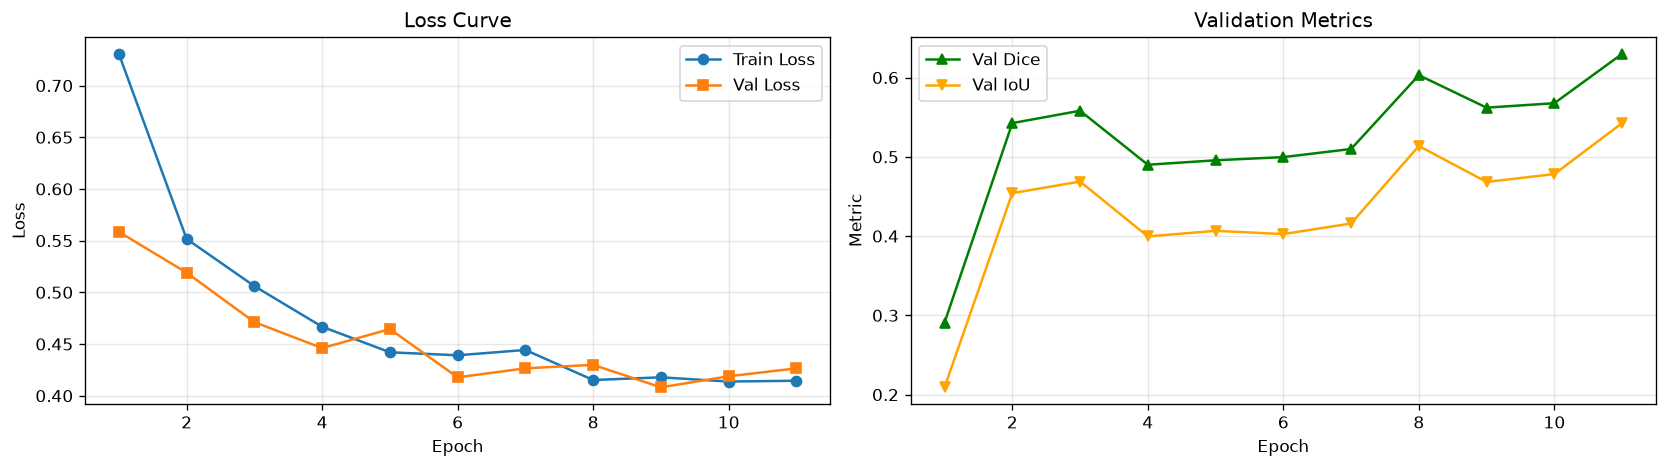

In [6]:
v2_ckpt_path = project_root / 'checkpoints' / 'unet_resnet34_v2' / 'best_model.pth'
ckpt_to_inspect = v2_ckpt_path if v2_ckpt_path.is_file() else project_root / 'checkpoints' / 'unet_resnet34' / 'best_model.pth'

ckpt = load_checkpoint(ckpt_to_inspect, model, map_location=device)
print(f'Inspecting {ckpt_to_inspect.parent.name}/{ckpt_to_inspect.name} (Epoch: {ckpt.get("epoch")})')

history = ckpt.get('history', [])
if history and 'train_loss' in history[0]:
    epochs = [h['epoch'] for h in history]
    train_losses = [h['train_loss'] for h in history]
    val_losses = [h['val_loss'] for h in history]
    val_dices = [h['val_dice'] for h in history]
    val_ious = [h['val_iou'] for h in history]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), dpi=120)
    ax1.plot(epochs, train_losses, label='Train Loss', marker='o')
    ax1.plot(epochs, val_losses, label='Val Loss', marker='s')
    ax1.set(xlabel='Epoch', ylabel='Loss', title='Loss Curve')
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.plot(epochs, val_dices, label='Val Dice', marker='^', color='green')
    ax2.plot(epochs, val_ious, label='Val IoU', marker='v', color='orange')
    ax2.set(xlabel='Epoch', ylabel='Metric', title='Validation Metrics')
    ax2.legend()
    ax2.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 6. Baseline vs. v2 Model Comparison Workflow

Evaluates and compares the original baseline (`checkpoints/unet_resnet34/best_model.pth`) and v2 (`checkpoints/unet_resnet34_v2/best_model.pth`) on the exact same validation images using full-resolution tiled inference.

In [7]:
# Load Baseline Model (v1)
model_v1 = build_model(pretrained=False).to(device)
load_checkpoint(project_root / 'checkpoints' / 'unet_resnet34' / 'best_model.pth', model_v1, map_location=device)
model_v1.eval()

# Load v2 Model if trained (or compare against current initialized v2 model)
model_v2 = build_model(pretrained=True).to(device)
if v2_ckpt_path.is_file():
    load_checkpoint(v2_ckpt_path, model_v2, map_location=device)
    model_v2_name = 'U-Net ResNet34 v2 (Trained)'
else:
    model_v2_name = 'U-Net ResNet34 v2 (Pretrained Init)'
model_v2.eval()

# Compare on sample validation images (or full validation set)
eval_indices = val_indices[:5]  # demonstration on first 5 validation images
comp_results = compare_models(
    model_a=model_v1,
    model_b=model_v2,
    dataset=val_eval_dataset,
    sample_indices=eval_indices,
    device=device,
    threshold_a=0.75,
    min_area_a=300,
    threshold_b=0.75,
    min_area_b=300,
    model_a_name='Baseline U-Net (v1)',
    model_b_name=model_v2_name,
)

print('--- Model Comparison Table ---')
display(comp_results['comparison_table'])

[2026-10-31 08:04:19] [INFO] [filament_seg.model]: Initialized Unet model with backbone resnet34 (weights: None, in_channels: 1, classes: 1)


[2026-10-31 08:04:19] [INFO] [filament_seg.train]: Loaded checkpoint from C:\Users\Vinny\Project\Kaggle\Solar Filament Segmentation\checkpoints\unet_resnet34\best_model.pth (epoch: 11, best_metric: 0.6298975355432193)


[2026-10-31 08:04:19] [INFO] [filament_seg.model]: Initialized Unet model with backbone resnet34 (weights: imagenet, in_channels: 1, classes: 1)


[2026-10-31 08:04:19] [INFO] [filament_seg.evaluate]: Comparing Baseline U-Net (v1) vs U-Net ResNet34 v2 (Pretrained Init) on 5 validation images...


--- Model Comparison Table ---


,Metric,Baseline U-Net (v1),U-Net ResNet34 v2 (Pretrained Init),Delta (v2 - v1)
0,Macro Dice,0.477246,0.000000,-0.477246
1,Micro (Global) Dice,0.615389,0.000000,-0.615389
2,Macro IoU,0.355766,0.000000,-0.355766
3,Pixel Precision,0.381584,0.000000,-0.381584
4,Pixel Recall,0.694053,0.000000,-0.694053
5,Global Panoptic Quality (PQ),0.310626,0.000000,-0.310626
6,Macro Panoptic Quality (PQ),0.233250,0.000000,-0.233250
7,True Positives (TP),13.000000,0.000000,-13.000000
8,False Positives (FP),20.000000,0.000000,-20.000000
9,False Negatives (FN),8.000000,21.000000,13.000000
